# Chapter 17: The Linear Model

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch17/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibrahimguney/statistical-theory/blob/main/notebooks/ch_17.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Verifying the Sampling Theory

$n=30$, an intercept and two explanatory variables ($p=3$); the design matrix is generated once and kept fixed, and only the errors are regenerated (the “fixed $X$” assumption).

*Source file:* `code/ch17/c17_1_verifying_sampling_theory.py`

In [2]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
n, p, sigma, R = 30, 3, 2.0, 100_000
X = np.c_[np.ones(n), rng.uniform(0, 10, n), rng.normal(5, 2, n)]
beta = np.array([1.0, 0.5, -0.3])
XtX_inv = np.linalg.inv(X.T @ X)
eps = rng.normal(0, sigma, (R, n))
Y = X @ beta + eps
B = Y @ X @ XtX_inv                     # each row is a beta_hat (X'X symmetric)
E = Y - B @ X.T
s2 = np.sum(E**2, axis=1) / (n - p)

print("E[beta_hat]        :", B.mean(0).round(4), "  true:", beta)
print("sd(beta_hat) MC    :", B.std(0).round(4))
print("sd theory          :", (sigma*np.sqrt(np.diag(XtX_inv))).round(4))
print(f"E[s^2] = {s2.mean():.4f} (sigma^2 = {sigma**2}) | Var[(n-p)s^2/sigma^2] = {np.var((n-p)*s2/sigma**2):.3f} (2(n-p) = {2*(n-p)})")
print(f"Corr(beta_hat_1, s^2) = {np.corrcoef(B[:, 1], s2)[0, 1]:+.4f}  (independence)")

tc = stats.t.ppf(0.975, n - p)
se1 = np.sqrt(s2 * XtX_inv[1, 1])
print(f"coverage of 95% t-interval for beta_1 = {np.mean(np.abs(B[:, 1] - beta[1]) <= tc*se1):.4f}")

# F-test: H0: beta_1 = beta_2 = 0 ; size (H0 true) and power (H0 false)
C = np.array([[0, 1, 0], [0, 0, 1]]); q = 2
M = np.linalg.inv(C @ XtX_inv @ C.T)
def F_stat(Bm, s2v):
    D = Bm @ C.T
    return np.einsum("ij,jk,ik->i", D, M, D) / q / s2v
Y0 = X @ np.array([1.0, 0.0, 0.0]) + eps
B0 = Y0 @ X @ XtX_inv; s20 = np.sum((Y0 - B0 @ X.T)**2, 1)/(n - p)
Fk = stats.f.ppf(0.95, q, n - p)
print(f"F-test size = {np.mean(F_stat(B0, s20) > Fk):.4f} (0.05) | power (true beta) = {np.mean(F_stat(B, s2) > Fk):.4f}")

E[beta_hat]        : [ 1.0016  0.5006 -0.3007]   true: [ 1.   0.5 -0.3]
sd(beta_hat) MC    : [1.4755 0.1257 0.2308]
sd theory          : [1.476  0.1257 0.2311]
E[s^2] = 3.9999 (sigma^2 = 4.0) | Var[(n-p)s^2/sigma^2] = 53.873 (2(n-p) = 54)
Corr(beta_hat_1, s^2) = +0.0027  (independence)
coverage of 95% t-interval for beta_1 = 0.9504
F-test size = 0.0494 (0.05) | power (true beta) = 0.9590


## Gauss–Markov: LS versus the Endpoint Estimator; ANOVA

*Source file:* `code/ch17/c17_2_gauss_markov_ls_vs_endpoint_anova.py`

In [3]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
n, R = 20, 200_000
x = np.arange(1, n + 1, dtype=float)
Y = 2.0 + 0.7*x + rng.normal(0, 1.5, (R, n))
xc = x - x.mean()
b_ls = (Y @ xc) / np.sum(xc**2)
b_end = (Y[:, -1] - Y[:, 0]) / (x[-1] - x[0])
print(f"LS slope  : mean={b_ls.mean():.4f}, Var={b_ls.var():.5f}")
print(f"Endpoints : mean={b_end.mean():.4f}, Var={b_end.var():.5f}")
print(f"Variance ratio = {b_end.var()/b_ls.var():.3f} | theory n(n+1)/(6(n-1)) = {n*(n+1)/(6*(n-1)):.3f}")

# One-way ANOVA: F by hand, the general C*beta formula and scipy
g = [rng.normal(m, 2.0, k) for m, k in [(10, 8), (11, 10), (13, 7)]]
y = np.concatenate(g); N, kgr = y.size, len(g)
ybar = y.mean()
F_hand = (sum(len(a)*(a.mean() - ybar)**2 for a in g)/(kgr - 1)) / (sum(((a - a.mean())**2).sum() for a in g)/(N - kgr))
Xg = np.zeros((N, kgr)); s = 0
for j, a in enumerate(g):
    Xg[s:s + len(a), j] = 1; s += len(a)
bh = np.linalg.solve(Xg.T @ Xg, Xg.T @ y); s2g = np.sum((y - Xg @ bh)**2)/(N - kgr)
Cg = np.array([[1, -1, 0], [1, 0, -1]])
d = Cg @ bh
F_gen = d @ np.linalg.solve(Cg @ np.linalg.inv(Xg.T @ Xg) @ Cg.T, d) / 2 / s2g
print(f"ANOVA F: by hand={F_hand:.4f} | general linear hypothesis={F_gen:.4f} | scipy f_oneway={stats.f_oneway(*g).statistic:.4f}"
      f" | p={stats.f_oneway(*g).pvalue:.4f}")

LS slope  : mean=0.7001, Var=0.00340
Endpoints : mean=0.7004, Var=0.01247
Variance ratio = 3.664 | theory n(n+1)/(6(n-1)) = 3.684
ANOVA F: by hand=1.4160 | general linear hypothesis=1.4160 | scipy f_oneway=1.4160 | p=0.2640


## Non-Normal Errors, Heteroscedasticity and Sandwich Standard Errors

*Source file:* `code/ch17/c17_3_nonnormal_errors_heteroscedasticity_sandwich.py`

n= 10 | skewed errors: classical=0.955 | heteroscedastic: classical=0.929, sandwich=0.896
n= 50 | skewed errors: classical=0.950 | heteroscedastic: classical=0.931, sandwich=0.937


n=200 | skewed errors: classical=0.951 | heteroscedastic: classical=0.931, sandwich=0.950


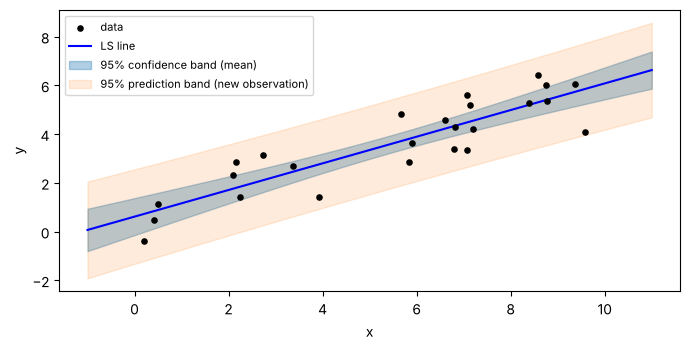

In [4]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
R = 20_000
def coverage(n, err, sandwich=False):
    x = np.linspace(0, 10, n); X = np.c_[np.ones(n), x]
    XtX_inv = np.linalg.inv(X.T @ X)
    eps = err(x, (R, n))
    Y = X @ np.array([1.0, 0.5]) + eps
    B = Y @ X @ XtX_inv; E = Y - B @ X.T
    if sandwich:
        meat = np.einsum("ri,ij,ik->rjk", E**2, X, X)            # sum e_i^2 x_i x_i'
        V = XtX_inv @ meat @ XtX_inv
        se = np.sqrt(V[:, 1, 1] * n/(n - 2))                     # HC1 correction
    else:
        se = np.sqrt(np.sum(E**2, 1)/(n - 2) * XtX_inv[1, 1])
    return np.mean(np.abs(B[:, 1] - 0.5) <= stats.t.ppf(0.975, n - 2)*se)

expo = lambda x, sh: rng.exponential(1, sh) - 1                 # skewed, constant variance
hetero = lambda x, sh: rng.normal(0, 1, sh) * (0.2 + 0.3*x)   # variance increases with x
for n in [10, 50, 200]:
    print(f"n={n:3d} | skewed errors: classical={coverage(n, expo):.3f} | heteroscedastic: classical={coverage(n, hetero):.3f},"
          f" sandwich={coverage(n, hetero, True):.3f}")

# Confidence and prediction bands
n = 25; x = np.sort(rng.uniform(0, 10, n)); X = np.c_[np.ones(n), x]
y = 1 + 0.5*x + rng.normal(0, 1, n)
bh = np.linalg.solve(X.T @ X, X.T @ y); s = np.sqrt(np.sum((y - X @ bh)**2)/(n - 2))
xx = np.linspace(-1, 11, 200); X0 = np.c_[np.ones_like(xx), xx]
q0 = np.einsum("ij,jk,ik->i", X0, np.linalg.inv(X.T @ X), X0); t = stats.t.ppf(0.975, n - 2)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(x, y, s=14, color="k", zorder=3, label="data")
ax.plot(xx, X0 @ bh, "b", label="LS line")
ax.fill_between(xx, X0 @ bh - t*s*np.sqrt(q0), X0 @ bh + t*s*np.sqrt(q0), alpha=0.35, color="tab:blue", label="95% confidence band (mean)")
ax.fill_between(xx, X0 @ bh - t*s*np.sqrt(1 + q0), X0 @ bh + t*s*np.sqrt(1 + q0), alpha=0.15, color="tab:orange", label="95% prediction band (new observation)")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8, loc="upper left"); fig.tight_layout(); fig.savefig("regresyon_bant.pdf")